# Détection de fraude Mobile Money via Graph Learning Dynamique

## Notebook 01 - Compréhension des données PaySim - Version améliorée

**Projet de Fin d'Études - Master 2 Big Data & Intelligence Artificielle**

---

### Objectif

Ce notebook vise à comprendre la structure, la qualité et les contraintes du dataset **PaySim** avant toute analyse exploratoire approfondie ou modélisation.

Il répond aux questions suivantes :

- Que contient le dataset ?
- Quelles variables sont disponibles ?
- Quelle est la qualité des données ?
- Existe-t-il des anomalies évidentes ?
- Quelles contraintes influenceront les modèles classiques, les GNN statiques et les modèles dynamiques ?

> Aucune transformation majeure ni suppression définitive n'est réalisée ici.

## Sommaire

1. Introduction  
2. Importation des bibliothèques  
3. Chargement des données  
4. Aperçu général  
5. Structure du dataset  
6. Types de données  
7. Statistiques descriptives  
8. Valeurs manquantes  
9. Doublons  
10. Variable cible  
11. Types de transactions  
12. Identifiants et comptes  
13. Dimension temporelle  
14. Cohérence et valeurs atypiques  
15. Contraintes et limites  
16. Executive Summary

# 1. Introduction

## Contexte métier

Le Mobile Money facilite les transferts, paiements et retraits à partir d'un téléphone mobile. Cette croissance s'accompagne toutefois de risques de fraude.

Les schémas frauduleux peuvent dépendre :

- des caractéristiques d'une transaction ;
- du comportement historique d'un compte ;
- des relations entre plusieurs comptes ;
- de la succession temporelle des opérations.

## Objectif métier

Construire un système capable de détecter rapidement les transactions suspectes afin de réduire les pertes, prioriser les alertes et identifier des comptes ou réseaux à risque.

## Objectif Data Science

Le projet comparera :

1. des modèles classiques de Machine Learning ;
2. des GNN statiques ;
3. des modèles de Graph Learning dynamique, notamment TGN ou EvolveGCN.

### Question de recherche

> Dans quelle mesure l'intégration de la structure relationnelle et de la dynamique temporelle améliore-t-elle la détection de fraude par rapport aux modèles tabulaires classiques ?

# 2. Importation des bibliothèques

Les bibliothèques sont chargées avec une configuration cohérente pour pandas et les visualisations.

In [35]:
# Manipuler les données
from pathlib import Path
from time import perf_counter
import json
import math
import sys
import warnings

import numpy as np
import pandas as pd

# Créer les visualisations
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

# Afficher du Markdown dynamique
from IPython.display import Markdown, display

# Masquer les avertissements non bloquants
warnings.filterwarnings("ignore")

# Configurer pandas
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Configurer les graphiques
sns.set_theme(style="whitegrid", context="notebook")

COLORS = {
    "primary": "#2563EB",
    "secondary": "#0F766E",
    "fraud": "#DC2626",
    "legitimate": "#16A34A",
    "warning": "#F59E0B",
    "neutral": "#64748B",
}

RANDOM_STATE = 42

print("Environnement initialisé avec succès.")

Environnement initialisé avec succès.


In [36]:
# Documenter les versions
versions = pd.DataFrame(
    {
        "Bibliothèque": [
            "Python",
            "pandas",
            "numpy",
            "matplotlib",
            "seaborn",
        ],
        "Version": [
            sys.version.split()[0],
            pd.__version__,
            np.__version__,
            matplotlib.__version__,
            sns.__version__,
        ],
    }
)

display(versions)

,Bibliothèque,Version
0,Python,3.13.7
1,pandas,3.0.3
2,numpy,2.2.6
3,matplotlib,3.10.8
4,seaborn,0.13.2


### Observation

Les versions utilisées sont affichées afin de documenter l'environnement.

### Interprétation

Cette information améliore la reproductibilité et facilite le diagnostic des incompatibilités.

### Impact sur le projet

Les versions seront reprises dans `requirements.txt` ou `environment.yml`.

### Décision

L'environnement technique sera documenté dans le dépôt GitHub.

# 3. Chargement des données

Arborescence recommandée :

```text
MobileMoney-Fraud-GNN/
├── data/
│   └── raw/
│       └── paysim.csv
└── notebooks/
    └── 01_data_understanding.ipynb
```

Le chemin peut également être défini manuellement.

In [37]:
# Indiquer un chemin manuel si nécessaire
MANUAL_DATA_PATH = None

# Déterminer la racine du projet
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name.lower() == "notebooks" else current_dir
raw_dir = project_root / "data" / "raw"

# Sélectionner le fichier CSV
if MANUAL_DATA_PATH is not None:
    data_path = Path(MANUAL_DATA_PATH)
else:
    csv_files = sorted(raw_dir.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(
            "Aucun fichier CSV trouvé dans data/raw. "
            "Place PaySim dans ce dossier ou renseigne MANUAL_DATA_PATH."
        )

    if len(csv_files) > 1:
        print("Plusieurs fichiers CSV ont été trouvés :")
        for index, file in enumerate(csv_files, start=1):
            print(f"{index}. {file.name}")
        print("\nLe premier fichier sera utilisé.")

    data_path = csv_files[0]

print(f"Fichier sélectionné : {data_path}")

Fichier sélectionné : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\data\raw\paysim.csv


In [38]:
# Charger le dataset
start_time = perf_counter()
df = pd.read_csv(data_path)
loading_time = perf_counter() - start_time

# Calculer les informations générales
n_rows, n_columns = df.shape
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
file_size_mb = data_path.stat().st_size / (1024 ** 2)

loading_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Nombre de lignes",
            "Nombre de colonnes",
            "Taille du fichier",
            "Mémoire occupée",
            "Temps de chargement",
        ],
        "Valeur": [
            f"{n_rows:,}",
            f"{n_columns:,}",
            f"{file_size_mb:,.2f} Mo",
            f"{memory_mb:,.2f} Mo",
            f"{loading_time:,.2f} secondes",
        ],
    }
)

display(loading_summary)

,Indicateur,Valeur
0,Nombre de lignes,"6,362,620"
1,Nombre de colonnes,11
2,Taille du fichier,470.67 Mo
3,Mémoire occupée,706.22 Mo
4,Temps de chargement,19.14 secondes


In [39]:
# Interpréter le chargement
volume_level = (
    "très important"
    if n_rows >= 1_000_000
    else "intermédiaire"
    if n_rows >= 100_000
    else "relativement limité"
)

display(
    Markdown(
        f"""
### Observation

Le dataset contient **{n_rows:,} lignes** et **{n_columns} colonnes**.  
Il occupe environ **{memory_mb:,.2f} Mo en mémoire** et son chargement a pris **{loading_time:,.2f} secondes**.

### Interprétation

Le volume est {volume_level}. Les colonnes textuelles peuvent occuper une part importante de la mémoire.

### Impact sur le projet

Les calculs devront être vectorisés et certaines visualisations utiliseront un échantillon, tandis que les statistiques essentielles resteront calculées sur l'ensemble des données.

### Décision

Le dataset complet est conservé. L'optimisation des types sera étudiée dans la préparation des données.
"""
    )
)


### Observation

Le dataset contient **6,362,620 lignes** et **11 colonnes**.  
Il occupe environ **706.22 Mo en mémoire** et son chargement a pris **19.14 secondes**.

### Interprétation

Le volume est très important. Les colonnes textuelles peuvent occuper une part importante de la mémoire.

### Impact sur le projet

Les calculs devront être vectorisés et certaines visualisations utiliseront un échantillon, tandis que les statistiques essentielles resteront calculées sur l'ensemble des données.

### Décision

Le dataset complet est conservé. L'optimisation des types sera étudiée dans la préparation des données.


# 4. Aperçu général

Les premières lignes, les dernières lignes et un échantillon aléatoire permettent de vérifier rapidement le format des enregistrements.

In [40]:
# Afficher plusieurs vues du dataset
print("Premières lignes")
display(df.head())

print("Dernières lignes")
display(df.tail())

print("Échantillon aléatoire")
display(df.sample(n=min(5, len(df)), random_state=RANDOM_STATE))

Premières lignes


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


Dernières lignes


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,"339,682.13",C786484425,"339,682.13",0.00,C776919290,0.00,"339,682.13",1,0
6362616,743,TRANSFER,"6,311,409.28",C1529008245,"6,311,409.28",0.00,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,"6,311,409.28",C1162922333,"6,311,409.28",0.00,C1365125890,"68,488.84","6,379,898.11",1,0
6362618,743,TRANSFER,"850,002.52",C1685995037,"850,002.52",0.00,C2080388513,0.00,0.00,1,0
6362619,743,CASH_OUT,"850,002.52",C1280323807,"850,002.52",0.00,C873221189,"6,510,099.11","7,360,101.63",1,0


Échantillon aléatoire


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3737323,278,CASH_IN,"330,218.42",C632336343,"20,866.00","351,084.42",C834976624,"452,419.57","122,201.15",0,0
264914,15,PAYMENT,"11,647.08",C1264712553,"30,370.00","18,722.92",M215391829,0.00,0.00,0,0
85647,10,CASH_IN,"152,264.21",C1746846248,"106,589.00","258,853.21",C1607284477,"201,303.01","49,038.80",0,0
5899326,403,TRANSFER,"1,551,760.63",C333676753,0.00,0.00,C1564353608,"3,198,359.45","4,750,120.08",0,0
2544263,206,CASH_IN,"78,172.30",C813403091,"2,921,331.58","2,999,503.88",C1091768874,"415,821.90","337,649.60",0,0


### Observation

Chaque ligne représente une transaction avec un repère temporel, un type, un montant, un émetteur, un destinataire, des soldes et une cible de fraude.

### Interprétation

Le dataset combine trois dimensions :

- tabulaire ;
- relationnelle ;
- temporelle.

### Impact sur le projet

Les comptes pourront devenir des nœuds, les transactions des arêtes et `step` l'ordre des événements.

### Décision

La signification et le rôle métier de chaque colonne seront documentés.

# 5. Structure du dataset

## Liste des colonnes et dictionnaire attendu

In [41]:
# Afficher la liste des colonnes
columns_df = pd.DataFrame(
    {
        "Position": range(1, len(df.columns) + 1),
        "Colonne": df.columns,
    }
)

display(columns_df)

,Position,Colonne
0,1,step
1,2,type
2,3,amount
3,4,nameOrig
4,5,oldbalanceOrg
5,6,newbalanceOrig
6,7,nameDest
7,8,oldbalanceDest
8,9,newbalanceDest
9,10,isFraud


In [42]:
# Construire le dictionnaire des variables PaySim
data_dictionary = pd.DataFrame(
    [
        ("step", "Temporelle", "Pas de temps de la simulation."),
        ("type", "Catégorielle", "Type d'opération financière."),
        ("amount", "Numérique", "Montant de la transaction."),
        ("nameOrig", "Identifiant", "Compte émetteur."),
        ("oldbalanceOrg", "Numérique", "Solde émetteur avant transaction."),
        ("newbalanceOrig", "Numérique", "Solde émetteur après transaction."),
        ("nameDest", "Identifiant", "Compte destinataire."),
        ("oldbalanceDest", "Numérique", "Solde destinataire avant transaction."),
        ("newbalanceDest", "Numérique", "Solde destinataire après transaction."),
        ("isFraud", "Cible", "Indique si la transaction est frauduleuse."),
        ("isFlaggedFraud", "Indicateur", "Alerte produite par une règle métier."),
    ],
    columns=["Variable", "Type métier", "Description"],
)

data_dictionary["Présente"] = data_dictionary["Variable"].isin(df.columns)
display(data_dictionary)

expected_columns = set(data_dictionary["Variable"])
actual_columns = set(df.columns)

print("Colonnes attendues absentes :", sorted(expected_columns - actual_columns) or "Aucune")
print("Colonnes supplémentaires :", sorted(actual_columns - expected_columns) or "Aucune")

,Variable,Type métier,Description,Présente
0,step,Temporelle,Pas de temps de la simulation.,True
1,type,Catégorielle,Type d'opération financière.,True
2,amount,Numérique,Montant de la transaction.,True
3,nameOrig,Identifiant,Compte émetteur.,True
4,oldbalanceOrg,Numérique,Solde émetteur avant transaction.,True
5,newbalanceOrig,Numérique,Solde émetteur après transaction.,True
6,nameDest,Identifiant,Compte destinataire.,True
7,oldbalanceDest,Numérique,Solde destinataire avant transaction.,True
8,newbalanceDest,Numérique,Solde destinataire après transaction.,True
9,isFraud,Cible,Indique si la transaction est frauduleuse.,True


Colonnes attendues absentes : Aucune
Colonnes supplémentaires : Aucune


### Observation

La structure réelle est comparée au schéma standard de PaySim.

### Interprétation

Une différence peut signaler une autre version du dataset ou un prétraitement antérieur.

### Impact sur le projet

Les notebooks utiliseront les colonnes réellement disponibles.

### Décision

Toute différence de schéma sera documentée.

# 6. Types de données

In [43]:
# Résumer les types techniques
dtype_summary = pd.DataFrame(
    {
        "Colonne": df.columns,
        "Type pandas": df.dtypes.astype(str).values,
        "Valeurs non nulles": df.notna().sum().values,
        "Valeurs uniques": [df[col].nunique(dropna=False) for col in df.columns],
    }
)

display(dtype_summary)

,Colonne,Type pandas,Valeurs non nulles,Valeurs uniques
0,step,int64,6362620,743
1,type,str,6362620,5
2,amount,float64,6362620,5316900
3,nameOrig,str,6362620,6353307
4,oldbalanceOrg,float64,6362620,1845844
5,newbalanceOrig,float64,6362620,2682586
6,nameDest,str,6362620,2722362
7,oldbalanceDest,float64,6362620,3614697
8,newbalanceDest,float64,6362620,3555499
9,isFraud,int64,6362620,2


In [44]:
# Identifier les rôles des variables
target_columns = [col for col in ["isFraud"] if col in df.columns]
identifier_columns = [col for col in ["nameOrig", "nameDest"] if col in df.columns]
temporal_columns = [col for col in ["step"] if col in df.columns]
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

roles_summary = pd.DataFrame(
    {
        "Rôle": [
            "Numériques",
            "Catégorielles",
            "Temporelles",
            "Identifiants",
            "Cible",
        ],
        "Colonnes": [
            ", ".join(numerical_columns) or "Aucune",
            ", ".join(categorical_columns) or "Aucune",
            ", ".join(temporal_columns) or "Aucune",
            ", ".join(identifier_columns) or "Aucune",
            ", ".join(target_columns) or "Aucune",
        ],
    }
)

display(roles_summary)

# Examiner la mémoire par colonne
memory_by_column = df.memory_usage(deep=True).sort_values(ascending=False).to_frame("Octets")
memory_by_column["Mémoire en Mo"] = memory_by_column["Octets"] / (1024 ** 2)
display(memory_by_column.head(10))

,Rôle,Colonnes
0,Numériques,"step, amount, oldbalanceOrg, newbalanceOrig, o..."
1,Catégorielles,"type, nameOrig, nameDest"
2,Temporelles,step
3,Identifiants,"nameOrig, nameDest"
4,Cible,isFraud


,Octets,Mémoire en Mo
nameOrig,117596000,112.15
nameDest,117592365,112.14
type,98126845,93.58
step,50900960,48.54
oldbalanceDest,50900960,48.54
amount,50900960,48.54
oldbalanceOrg,50900960,48.54
newbalanceOrig,50900960,48.54
isFraud,50900960,48.54
newbalanceDest,50900960,48.54


### Observation

Les identifiants sont généralement stockés comme chaînes et présentent une forte cardinalité.

### Interprétation

Ils ne doivent pas être encodés directement par One-Hot Encoding, mais ils sont indispensables à la construction du graphe.

### Impact sur le projet

Chaque variable sera traitée selon son rôle métier.

### Décision

Aucun encodage des identifiants n'est réalisé dans ce notebook.

# 7. Statistiques descriptives

In [45]:
# Décrire les variables numériques
numeric_description = df.describe(
    include=[np.number],
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99],
).T

display(numeric_description)

# Décrire les variables catégorielles
if categorical_columns:
    display(df[categorical_columns].describe().T)

# Mesurer la cardinalité
cardinality_summary = pd.DataFrame(
    {
        "Colonne": df.columns,
        "Valeurs uniques": [df[col].nunique(dropna=False) for col in df.columns],
        "Taux d'unicité (%)": [
            100 * df[col].nunique(dropna=False) / len(df)
            for col in df.columns
        ],
    }
).sort_values("Valeurs uniques", ascending=False)

display(cardinality_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
step,"6,362,620.00",243.40,142.33,1.00,9.00,16.00,156.00,239.00,335.00,490.00,681.00,743.00
amount,"6,362,620.00","179,861.90","603,858.23",0.00,449.47,"2,224.10","13,389.57","74,871.94","208,721.48","518,634.20","1,615,979.47","92,445,516.64"
oldbalanceOrg,"6,362,620.00","833,883.10","2,888,242.67",0.00,0.00,0.00,0.00,"14,208.00","107,315.18","5,823,702.28","16,027,256.13","59,585,040.37"
newbalanceOrig,"6,362,620.00","855,113.67","2,924,048.50",0.00,0.00,0.00,0.00,0.00,"144,258.41","5,980,262.34","16,176,160.56","49,585,040.37"
oldbalanceDest,"6,362,620.00","1,100,701.67","3,399,180.11",0.00,0.00,0.00,0.00,"132,705.66","943,036.71","5,147,229.71","12,371,819.15","356,015,889.35"
newbalanceDest,"6,362,620.00","1,224,996.40","3,674,128.94",0.00,0.00,0.00,0.00,"214,661.44","1,111,909.25","5,515,715.90","13,137,866.94","356,179,278.92"
isFraud,"6,362,620.00",0.00,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
isFlaggedFraud,"6,362,620.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


,count,unique,top,freq
type,6362620,5,CASH_OUT,2237500
nameOrig,6362620,6353307,C2098525306,3
nameDest,6362620,2722362,C1286084959,113


,Colonne,Valeurs uniques,Taux d'unicité (%)
3,nameOrig,6353307,99.85
2,amount,5316900,83.56
7,oldbalanceDest,3614697,56.81
8,newbalanceDest,3555499,55.88
6,nameDest,2722362,42.79
5,newbalanceOrig,2682586,42.16
4,oldbalanceOrg,1845844,29.01
0,step,743,0.01
1,type,5,0.00
9,isFraud,2,0.00


### Observation

Les statistiques décrivent les ordres de grandeur, la dispersion, l'asymétrie et la cardinalité.

### Interprétation

Les montants et soldes transactionnels peuvent être fortement asymétriques, avec une minorité de valeurs très élevées.

### Impact sur le projet

Les modèles linéaires et neuronaux pourront nécessiter une mise à l'échelle ou une transformation adaptée.

### Décision

Les transformations seront évaluées uniquement après l'EDA.

# 8. Valeurs manquantes

,Valeurs manquantes,Pourcentage (%)
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


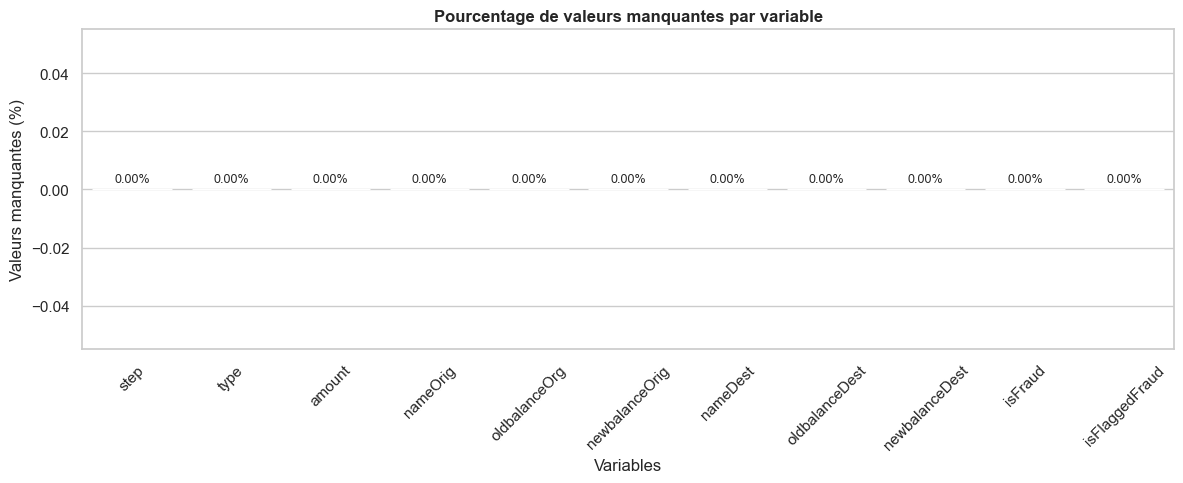

In [46]:
# Calculer les valeurs manquantes
missing_summary = pd.DataFrame(
    {
        "Valeurs manquantes": df.isna().sum(),
        "Pourcentage (%)": 100 * df.isna().mean(),
    }
).sort_values("Valeurs manquantes", ascending=False)

display(missing_summary)

# Visualiser les pourcentages
plot_data = missing_summary.reset_index()
plot_data.columns = ["Colonne", "Valeurs manquantes", "Pourcentage (%)"]

fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=plot_data,
    x="Colonne",
    y="Pourcentage (%)",
    color=COLORS["primary"],
    ax=ax,
)

ax.set_title("Pourcentage de valeurs manquantes par variable", fontweight="bold")
ax.set_xlabel("Variables")
ax.set_ylabel("Valeurs manquantes (%)")
ax.tick_params(axis="x", rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [47]:
# Interpréter les valeurs manquantes
total_missing = int(df.isna().sum().sum())
columns_with_missing = missing_summary[
    missing_summary["Valeurs manquantes"] > 0
].index.tolist()

if total_missing == 0:
    observation = "Aucune valeur manquante explicite n'a été détectée."
    decision = "Aucune imputation n'est nécessaire à ce stade."
else:
    observation = (
        f"{total_missing:,} valeurs manquantes sont présentes dans "
        f"{len(columns_with_missing)} colonne(s) : {', '.join(columns_with_missing)}."
    )
    decision = "Le mécanisme des valeurs manquantes sera étudié avant toute imputation."

display(
    Markdown(
        f"""
### Observation

{observation}

### Interprétation

L'absence de `NaN` ne garantit pas l'absence d'informations non renseignées. Certains zéros peuvent correspondre à une convention du simulateur.

### Impact sur le projet

Les soldes nuls devront être interprétés selon le type de compte et la transaction.

### Décision

{decision}
"""
    )
)


### Observation

Aucune valeur manquante explicite n'a été détectée.

### Interprétation

L'absence de `NaN` ne garantit pas l'absence d'informations non renseignées. Certains zéros peuvent correspondre à une convention du simulateur.

### Impact sur le projet

Les soldes nuls devront être interprétés selon le type de compte et la transaction.

### Décision

Aucune imputation n'est nécessaire à ce stade.


# 9. Doublons

Les doublons complets sont distingués des doublons métier potentiels. L'absence d'identifiant transactionnel unique impose de rester prudent.

In [48]:
# Rechercher les doublons complets
start_time = perf_counter()
complete_duplicate_mask = df.duplicated(keep=False)
n_complete_duplicate_rows = int(complete_duplicate_mask.sum())
duplicate_time = perf_counter() - start_time

duplicate_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Lignes dans un groupe de doublons complets",
            "Pourcentage de lignes concernées",
            "Temps de calcul",
        ],
        "Valeur": [
            f"{n_complete_duplicate_rows:,}",
            f"{100 * n_complete_duplicate_rows / len(df):.6f} %",
            f"{duplicate_time:.2f} secondes",
        ],
    }
)

display(duplicate_summary)

if n_complete_duplicate_rows > 0:
    display(df.loc[complete_duplicate_mask].head(20))
else:
    print("Aucun doublon complet détecté.")

,Indicateur,Valeur
0,Lignes dans un groupe de doublons complets,0
1,Pourcentage de lignes concernées,0.000000 %
2,Temps de calcul,12.88 secondes


Aucun doublon complet détecté.


In [49]:
# Définir une clé métier potentielle
business_key_candidates = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "nameDest",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]

business_key = [col for col in business_key_candidates if col in df.columns]

if business_key:
    business_duplicate_mask = df.duplicated(subset=business_key, keep=False)
    n_business_duplicate_rows = int(business_duplicate_mask.sum())

    print(
        "Lignes dans un doublon métier potentiel : "
        f"{n_business_duplicate_rows:,}"
    )
    print(
        "Pourcentage : "
        f"{100 * n_business_duplicate_rows / len(df):.6f} %"
    )
else:
    n_business_duplicate_rows = 0
    print("La clé métier ne peut pas être construite.")

Lignes dans un doublon métier potentiel : 0
Pourcentage : 0.000000 %


### Observation

Les doublons complets et potentiels sont comptés séparément.

### Interprétation

Deux lignes identiques peuvent représenter une duplication technique ou deux événements distincts au même pas de temps.

### Impact sur le projet

Une suppression automatique pourrait modifier le nombre de transactions et la structure du graphe.

### Décision

Aucun doublon n'est supprimé dans ce notebook.

# 10. Analyse de la variable cible

,Effectif,Pourcentage (%)
Légitime,6354407,99.87
Fraude,8213,0.13


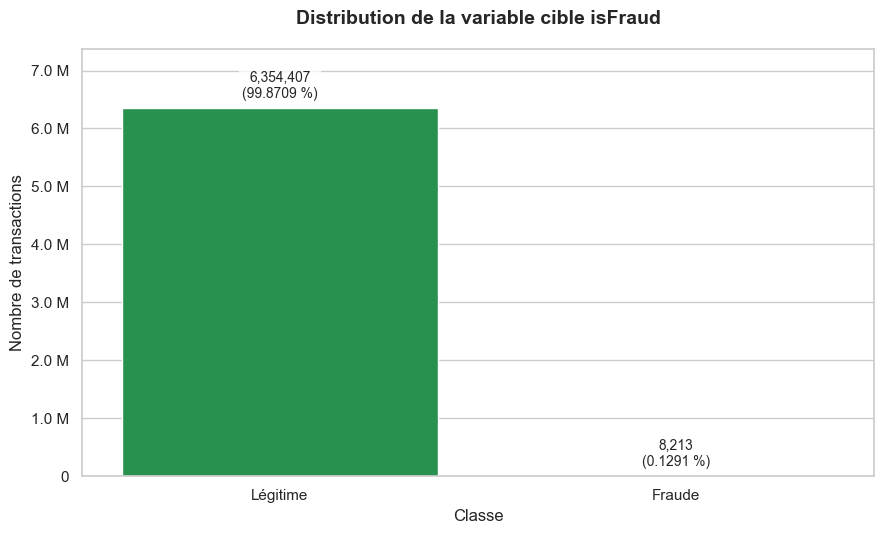

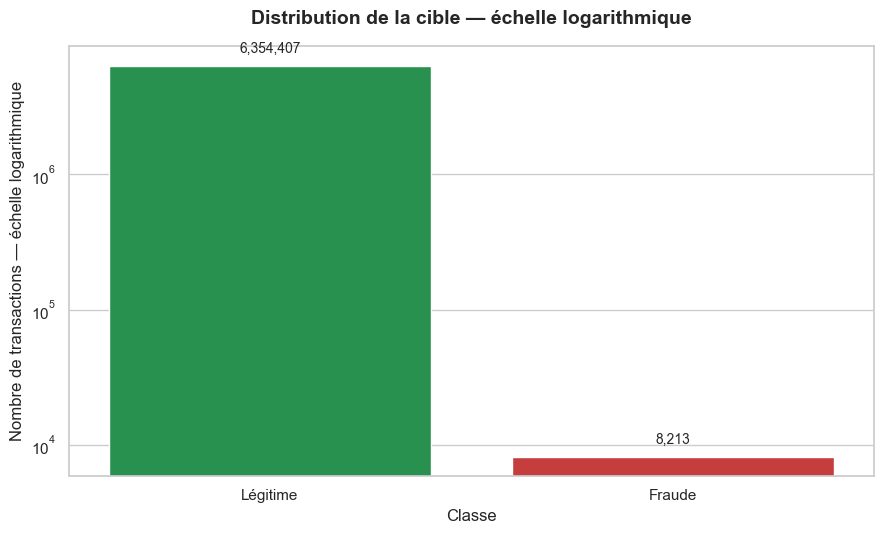

In [50]:
# Vérifier la cible
if "isFraud" not in df.columns:
    raise KeyError("La colonne cible isFraud est absente.")

# Calculer la distribution
target_counts = df["isFraud"].value_counts(dropna=False).sort_index()
target_percentages = (
    100
    * df["isFraud"]
    .value_counts(normalize=True, dropna=False)
    .sort_index()
)

target_distribution = pd.DataFrame(
    {
        "Effectif": target_counts,
        "Pourcentage (%)": target_percentages,
    }
)

target_distribution.index = [
    "Légitime" if value == 0 else "Fraude" if value == 1 else str(value)
    for value in target_distribution.index
]

display(target_distribution)

target_plot = target_distribution.reset_index()
target_plot.columns = ["Classe", "Effectif", "Pourcentage (%)"]

class_palette = {
    "Légitime": COLORS["legitimate"],
    "Fraude": COLORS["fraud"],
}

# Afficher la distribution sur une échelle normale
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.barplot(
    data=target_plot,
    x="Classe",
    y="Effectif",
    hue="Classe",
    palette=class_palette,
    legend=False,
    ax=ax,
)

ax.set_title(
    "Distribution de la variable cible isFraud",
    fontsize=14,
    fontweight="bold",
    pad=18,
)
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de transactions")
ax.set_ylim(0, target_plot["Effectif"].max() * 1.16)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: (
            f"{value / 1_000_000:.1f} M"
            if value >= 1_000_000
            else f"{value:,.0f}"
        )
    )
)

for index, row in target_plot.iterrows():
    ax.text(
        index,
        row["Effectif"] + target_plot["Effectif"].max() * 0.018,
        f'{row["Effectif"]:,.0f}\n({row["Pourcentage (%)"]:.4f} %)',
        ha="center",
        va="bottom",
        fontsize=10,
        bbox={
            "facecolor": "white",
            "alpha": 0.75,
            "edgecolor": "none",
            "pad": 2,
        },
    )

plt.tight_layout()
plt.show()

# Afficher une seconde vue logarithmique
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.barplot(
    data=target_plot,
    x="Classe",
    y="Effectif",
    hue="Classe",
    palette=class_palette,
    legend=False,
    ax=ax,
)

ax.set_yscale("log")
ax.set_title(
    "Distribution de la cible — échelle logarithmique",
    fontsize=14,
    fontweight="bold",
    pad=16,
)
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de transactions — échelle logarithmique")

for index, row in target_plot.iterrows():
    ax.text(
        index,
        row["Effectif"] * 1.18,
        f'{row["Effectif"]:,.0f}',
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

In [51]:
# Interpréter le déséquilibre
n_fraud = int((df["isFraud"] == 1).sum())
n_legitimate = int((df["isFraud"] == 0).sum())
fraud_rate = 100 * n_fraud / len(df)
imbalance_ratio = n_legitimate / n_fraud if n_fraud > 0 else np.inf

display(
    Markdown(
        f"""
### Observation

Le dataset contient **{n_fraud:,} fraudes** sur **{len(df):,} transactions**, soit **{fraud_rate:.6f} %**.

Le rapport de déséquilibre est d'environ **{imbalance_ratio:,.2f} transactions légitimes pour une fraude**.

### Interprétation

Un modèle peut obtenir une forte accuracy tout en détectant très peu de fraudes.

### Impact sur le projet

Les métriques principales seront le recall fraude, la précision, le F1-score, la PR-AUC, la ROC-AUC et les coûts métier.

### Décision

L'accuracy ne sera jamais utilisée seule pour choisir le meilleur modèle.
"""
    )
)


### Observation

Le dataset contient **8,213 fraudes** sur **6,362,620 transactions**, soit **0.129082 %**.

Le rapport de déséquilibre est d'environ **773.70 transactions légitimes pour une fraude**.

### Interprétation

Un modèle peut obtenir une forte accuracy tout en détectant très peu de fraudes.

### Impact sur le projet

Les métriques principales seront le recall fraude, la précision, le F1-score, la PR-AUC, la ROC-AUC et les coûts métier.

### Décision

L'accuracy ne sera jamais utilisée seule pour choisir le meilleur modèle.


# 11. Analyse rapide des types de transactions

,Effectif,Pourcentage (%)
type,,
CASH_OUT,2237500,35.17
PAYMENT,2151495,33.81
CASH_IN,1399284,21.99
TRANSFER,532909,8.38
DEBIT,41432,0.65


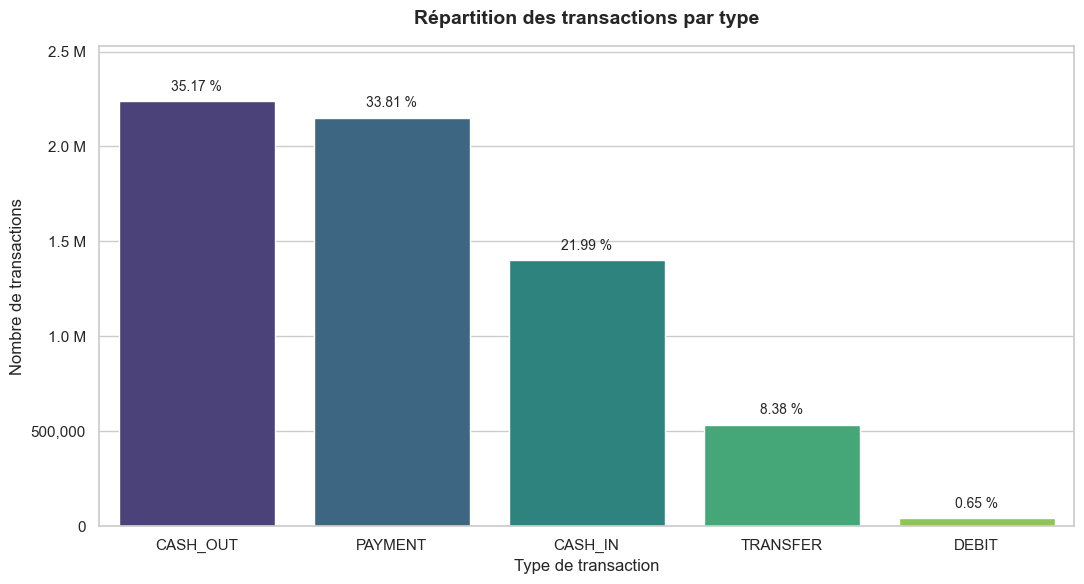

In [52]:
# Vérifier le type de transaction
if "type" not in df.columns:
    raise KeyError("La colonne type est absente.")

# Calculer la distribution
type_distribution = pd.DataFrame(
    {
        "Effectif": df["type"].value_counts(),
        "Pourcentage (%)": (
            100 * df["type"].value_counts(normalize=True)
        ),
    }
)

display(type_distribution)

# Visualiser les types
type_plot = type_distribution.reset_index()
type_plot.columns = ["Type", "Effectif", "Pourcentage (%)"]

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=type_plot,
    x="Type",
    y="Effectif",
    hue="Type",
    palette="viridis",
    legend=False,
    ax=ax,
)

ax.set_title(
    "Répartition des transactions par type",
    fontsize=14,
    fontweight="bold",
    pad=16,
)
ax.set_xlabel("Type de transaction")
ax.set_ylabel("Nombre de transactions")
ax.set_ylim(0, type_plot["Effectif"].max() * 1.13)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: (
            f"{value / 1_000_000:.1f} M"
            if value >= 1_000_000
            else f"{value:,.0f}"
        )
    )
)

for index, row in type_plot.iterrows():
    ax.text(
        index,
        row["Effectif"] + type_plot["Effectif"].max() * 0.018,
        f'{row["Pourcentage (%)"]:.2f} %',
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

,Transactions,Fraudes,Taux de fraude (%)
type,,,
CASH_OUT,2237500,4116,0.18
TRANSFER,532909,4097,0.77
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


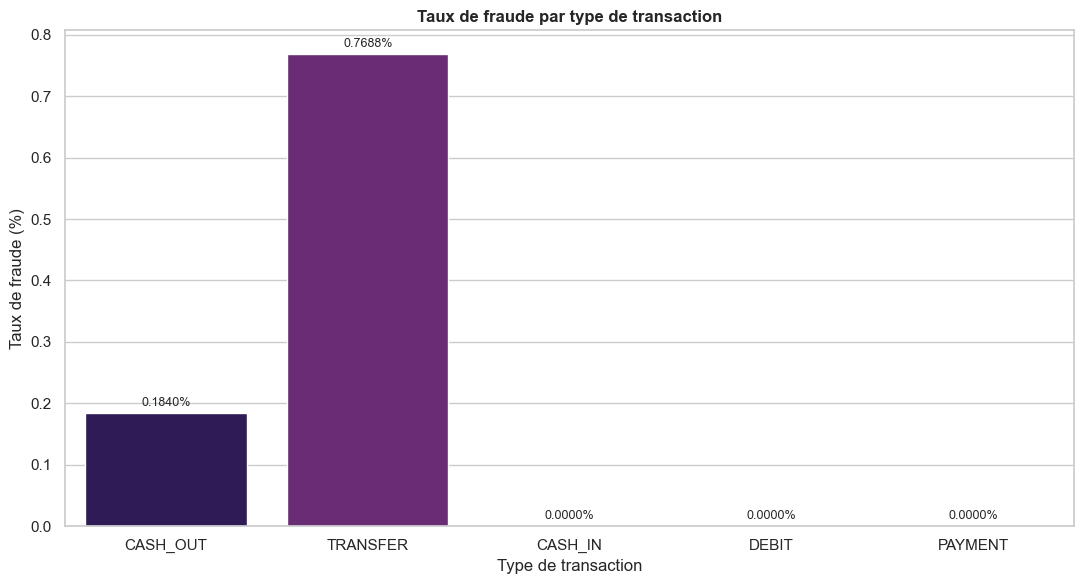

In [53]:
# Croiser le type et la fraude
fraud_by_type = (
    df.groupby("type", observed=True)["isFraud"]
    .agg(Transactions="size", Fraudes="sum", Taux_de_fraude="mean")
    .sort_values("Fraudes", ascending=False)
)

fraud_by_type["Taux de fraude (%)"] = 100 * fraud_by_type["Taux_de_fraude"]
fraud_by_type = fraud_by_type.drop(columns="Taux_de_fraude")

display(fraud_by_type)

# Visualiser le taux de fraude
fraud_type_plot = fraud_by_type.reset_index()

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=fraud_type_plot,
    x="type",
    y="Taux de fraude (%)",
    hue="type",
    palette="magma",
    legend=False,
    ax=ax,
)

ax.set_title("Taux de fraude par type de transaction", fontweight="bold")
ax.set_xlabel("Type de transaction")
ax.set_ylabel("Taux de fraude (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [54]:
# Interpréter les types
types_with_fraud = fraud_by_type[fraud_by_type["Fraudes"] > 0].index.tolist()
types_without_fraud = fraud_by_type[fraud_by_type["Fraudes"] == 0].index.tolist()

display(
    Markdown(
        f"""
### Observation

Fraudes observées dans : **{", ".join(types_with_fraud) if types_with_fraud else "aucun type"}**.  
Types sans fraude observée : **{", ".join(types_without_fraud) if types_without_fraud else "aucun"}**.

### Interprétation

Le type de transaction semble informatif, mais une règle propre au dataset synthétique ne doit pas être généralisée automatiquement à un système réel.

### Impact sur le projet

Une sélection limitée aux types fraudés pourrait donner une performance artificiellement élevée et retirer du contexte au graphe.

### Décision

Tous les types sont conservés pour l'analyse et la construction initiale du graphe.
"""
    )
)


### Observation

Fraudes observées dans : **CASH_OUT, TRANSFER**.  
Types sans fraude observée : **CASH_IN, DEBIT, PAYMENT**.

### Interprétation

Le type de transaction semble informatif, mais une règle propre au dataset synthétique ne doit pas être généralisée automatiquement à un système réel.

### Impact sur le projet

Une sélection limitée aux types fraudés pourrait donner une performance artificiellement élevée et retirer du contexte au graphe.

### Décision

Tous les types sont conservés pour l'analyse et la construction initiale du graphe.


# 12. Vérification des identifiants

In [55]:
# Vérifier les colonnes de comptes
required_ids = {"nameOrig", "nameDest"}

if not required_ids.issubset(df.columns):
    raise KeyError(
        f"Identifiants absents : {sorted(required_ids - set(df.columns))}"
    )

# Calculer les nombres de comptes
unique_orig = df["nameOrig"].nunique()
unique_dest = df["nameDest"].nunique()

orig_accounts = pd.Index(df["nameOrig"].unique())
dest_accounts = pd.Index(df["nameDest"].unique())
common_accounts = orig_accounts.intersection(dest_accounts)
all_accounts = orig_accounts.union(dest_accounts)

id_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Comptes émetteurs uniques",
            "Comptes destinataires uniques",
            "Comptes dans les deux rôles",
            "Comptes uniques au total",
            "Transactions auto-adressées",
        ],
        "Valeur": [
            f"{unique_orig:,}",
            f"{unique_dest:,}",
            f"{len(common_accounts):,}",
            f"{len(all_accounts):,}",
            f"{(df['nameOrig'] == df['nameDest']).sum():,}",
        ],
    }
)

display(id_summary)

,Indicateur,Valeur
0,Comptes émetteurs uniques,"6,353,307"
1,Comptes destinataires uniques,"2,722,362"
2,Comptes dans les deux rôles,"1,769"
3,Comptes uniques au total,"9,073,900"
4,Transactions auto-adressées,0


In [56]:
# Mesurer l'activité des comptes
origin_activity = df["nameOrig"].value_counts().rename("Transactions émises")
destination_activity = df["nameDest"].value_counts().rename("Transactions reçues")

account_activity = pd.concat(
    [origin_activity, destination_activity],
    axis=1,
).fillna(0)

account_activity["Transactions totales"] = (
    account_activity["Transactions émises"]
    + account_activity["Transactions reçues"]
)

account_activity = account_activity.sort_values(
    "Transactions totales",
    ascending=False,
)

display(account_activity.head(20))
display(
    account_activity.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).T
)

,Transactions émises,Transactions reçues,Transactions totales
C1286084959,0.00,113.00,113.00
C985934102,0.00,109.00,109.00
C665576141,0.00,105.00,105.00
C2083562754,0.00,102.00,102.00
C248609774,0.00,101.00,101.00
C1590550415,0.00,101.00,101.00
C451111351,0.00,99.00,99.00
C1789550256,0.00,99.00,99.00
C1360767589,0.00,98.00,98.00
C1023714065,0.00,97.00,97.00


,count,mean,std,min,50%,75%,90%,95%,99%,max
Transactions émises,"9,073,900.00",0.70,0.46,0.00,1.00,1.00,1.00,1.00,1.00,3.00
Transactions reçues,"9,073,900.00",0.70,2.71,0.00,0.00,1.00,1.00,2.00,14.00,113.00
Transactions totales,"9,073,900.00",1.40,2.57,1.00,1.00,1.00,1.00,2.00,14.00,113.00


In [57]:
# Examiner les préfixes des comptes
prefix_summary = pd.DataFrame(
    {
        "Émetteurs": df["nameOrig"].astype(str).str[0].value_counts(),
        "Destinataires": df["nameDest"].astype(str).str[0].value_counts(),
    }
).fillna(0)

display(prefix_summary)

,Émetteurs,Destinataires
C,"6,362,620.00",4211125
M,0.00,2151495


### Observation

Les comptes ont des niveaux d'activité différents et certains occupent les deux rôles.

### Interprétation

La structure correspond à un graphe orienté : comptes comme nœuds, transactions comme arêtes.

### Impact sur le projet

La cardinalité des identifiants empêche un encodage catégoriel classique, mais rend possible le Graph Learning.

### Décision

Une table de correspondance entre identifiants et indices numériques sera construite dans le notebook du graphe.

# 13. Vérification temporelle

La variable step représente l'unité temporelle du simulateur PaySim. Chaque step correspond approximativement à une heure d'activité. Contrairement à une agrégation par jour, l'analyse directement au niveau des steps respecte la granularité originale du jeu de données et permet d'observer plus fidèlement l'évolution de l'activité transactionnelle. Cette approche est particulièrement pertinente dans la perspective de la construction d'un graphe dynamique, où les interactions évoluent au fil du temps.

In [58]:
# Vérifier la variable temporelle
if "step" not in df.columns:
    raise KeyError("La colonne step est absente.")

step_min = df["step"].min()
step_max = df["step"].max()
n_unique_steps = df["step"].nunique()
estimated_days = math.ceil(step_max / 24)

temporal_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Premier step",
            "Dernier step",
            "Steps distincts",
            "Durée estimée en jours",
            "Steps manquants dans l'intervalle",
        ],
        "Valeur": [
            f"{step_min:,.0f}",
            f"{step_max:,.0f}",
            f"{n_unique_steps:,}",
            f"{estimated_days:,}",
            f"{(step_max - step_min + 1) - n_unique_steps:,.0f}",
        ],
    }
)

display(temporal_summary)

,Indicateur,Valeur
0,Premier step,1
1,Dernier step,743
2,Steps distincts,743
3,Durée estimée en jours,31
4,Steps manquants dans l'intervalle,0


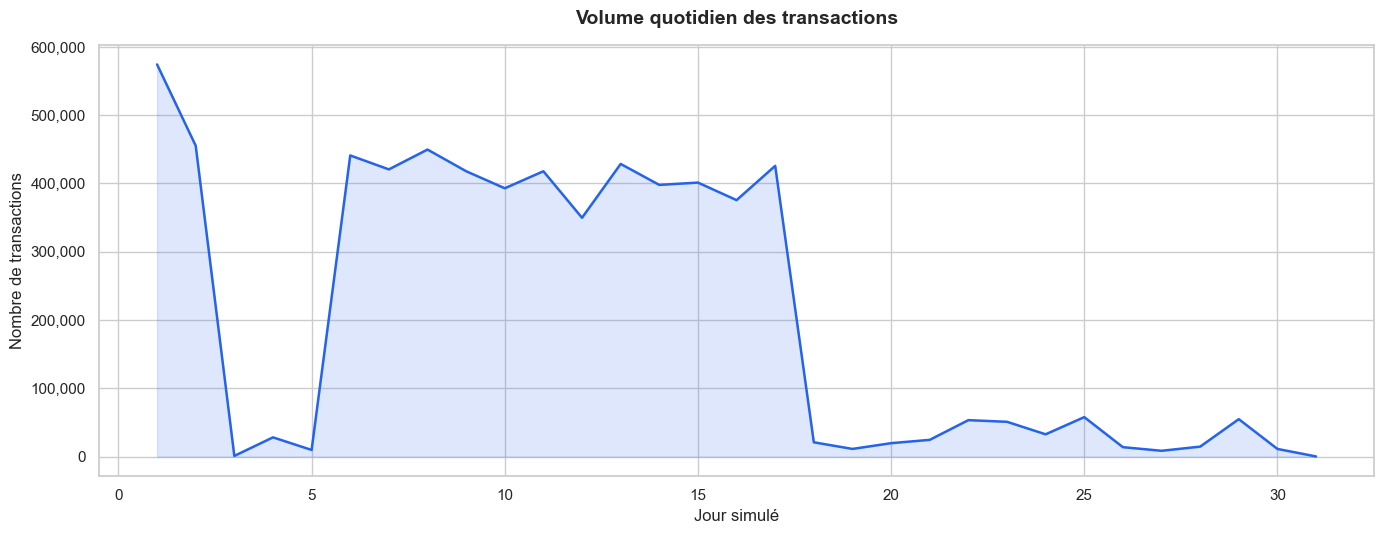

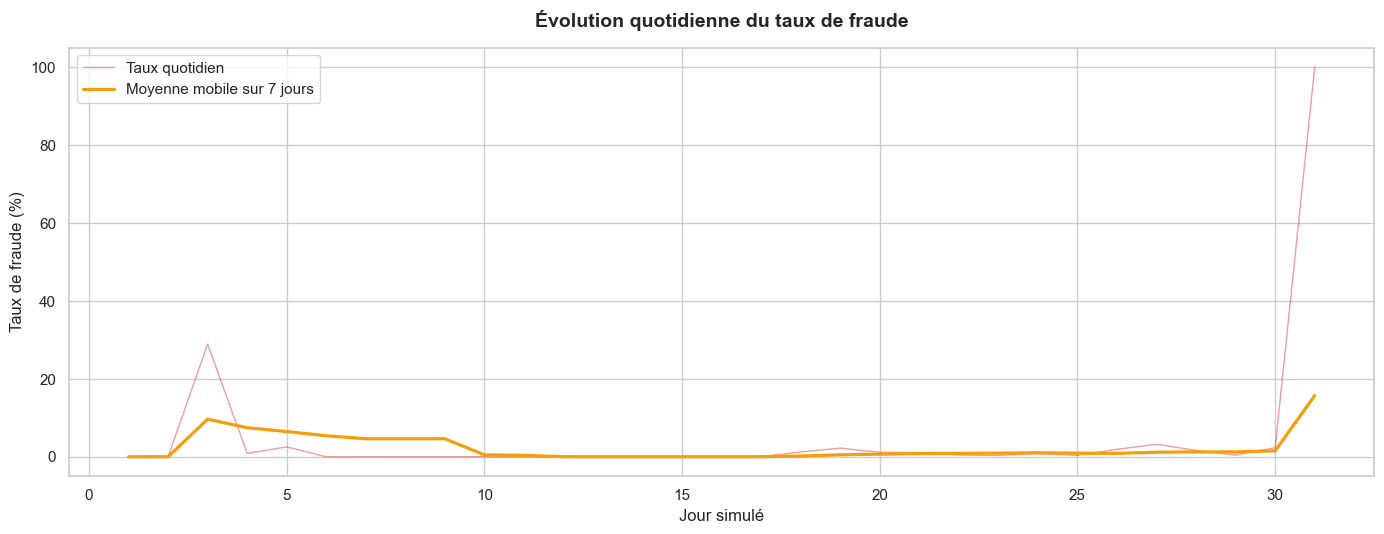

In [59]:
# Créer un indice de jour pour l'analyse
temporary_day = ((df["step"] - 1) // 24 + 1).astype("int32")

# Agréger les transactions par jour
activity_by_day = (
    df.assign(_day=temporary_day)
    .groupby("_day", observed=True)
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
        Montant_total=("amount", "sum"),
    )
)

activity_by_day["Taux de fraude (%)"] = (
    100
    * activity_by_day["Fraudes"]
    / activity_by_day["Transactions"]
)

activity_by_day["Taux de fraude mobile 7 jours (%)"] = (
    activity_by_day["Taux de fraude (%)"]
    .rolling(window=7, min_periods=1)
    .mean()
)

# Visualiser le volume quotidien
fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(
    activity_by_day.index,
    activity_by_day["Transactions"],
    color=COLORS["primary"],
    linewidth=1.8,
)

ax.fill_between(
    activity_by_day.index,
    activity_by_day["Transactions"],
    alpha=0.15,
    color=COLORS["primary"],
)

ax.set_title(
    "Volume quotidien des transactions",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Jour simulé")
ax.set_ylabel("Nombre de transactions")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

plt.tight_layout()
plt.show()

# Visualiser le taux de fraude quotidien
fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(
    activity_by_day.index,
    activity_by_day["Taux de fraude (%)"],
    color=COLORS["fraud"],
    linewidth=1,
    alpha=0.45,
    label="Taux quotidien",
)

ax.plot(
    activity_by_day.index,
    activity_by_day["Taux de fraude mobile 7 jours (%)"],
    color=COLORS["warning"],
    linewidth=2.3,
    label="Moyenne mobile sur 7 jours",
)

ax.set_title(
    "Évolution quotidienne du taux de fraude",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Jour simulé")
ax.set_ylabel("Taux de fraude (%)")
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

In [60]:
# Afficher le début et la fin des agrégations quotidiennes
print("Premiers jours")
display(activity_by_day.head())

print("Derniers jours")
display(activity_by_day.tail())

# Identifier les journées les plus actives
print("Journées avec le plus grand volume de transactions")
display(
    activity_by_day.nlargest(10, "Transactions")[
        ["Transactions", "Fraudes", "Taux de fraude (%)"]
    ]
)

# Identifier les journées avec le plus de fraudes
print("Journées avec le plus grand nombre de fraudes")
display(
    activity_by_day.nlargest(10, "Fraudes")[
        ["Transactions", "Fraudes", "Taux de fraude (%)"]
    ]
)

Premiers jours


,Transactions,Fraudes,Montant_total,Taux de fraude (%),Taux de fraude mobile 7 jours (%)
_day,,,,,
1,574255,271,"92,131,865,625.65",0.05,0.05
2,455238,309,"71,238,642,397.16",0.07,0.06
3,1070,310,"447,084,472.63",28.97,9.70
4,28240,262,"3,830,547,360.59",0.93,7.50
5,9789,252,"1,325,133,839.05",2.57,6.52


Derniers jours


,Transactions,Fraudes,Montant_total,Taux de fraude (%),Taux de fraude mobile 7 jours (%)
_day,,,,,
27,8578,280,"1,756,268,796.76",3.26,1.21
28,14661,248,"3,006,718,037.76",1.69,1.30
29,54890,260,"9,357,636,452.07",0.47,1.30
30,11287,268,"1,995,900,406.17",2.37,1.58
31,272,272,"448,086,234.84",100.00,15.74


Journées avec le plus grand volume de transactions


,Transactions,Fraudes,Taux de fraude (%)
_day,,,
1,574255,271,0.05
2,455238,309,0.07
8,449637,278,0.06
6,441005,228,0.05
13,428583,242,0.06
17,425766,320,0.08
7,420583,272,0.06
9,417919,255,0.06
11,417859,262,0.06


Journées avec le plus grand nombre de fraudes


,Transactions,Fraudes,Taux de fraude (%)
_day,,,
17,425766,320,0.08
3,1070,310,28.97
2,455238,309,0.07
12,349776,298,0.09
10,392945,282,0.07
24,32709,280,0.86
27,8578,280,3.26
8,449637,278,0.06
7,420583,272,0.06


### Observation

`step` ordonne les transactions et permet d'observer l'évolution de l'activité.

### Interprétation

Le temps définit l'ordre d'apparition des arêtes et peut révéler des séquences suspectes.

### Impact sur le projet

Un split aléatoire risquerait d'introduire une fuite d'information temporelle.

### Décision

Le protocole principal utilisera un découpage chronologique.

# 14. Vérifications de cohérence et valeurs atypiques

Les contrôles repèrent des anomalies apparentes. Ils ne constituent pas automatiquement des preuves d'erreur.

In [61]:
# Créer une fonction de comptage
def count_and_rate(mask, total):
    count = int(mask.sum())
    return count, 100 * count / total


# Vérifier les valeurs générales
checks = []

if "amount" in df.columns:
    count, rate = count_and_rate(df["amount"] < 0, len(df))
    checks.append(("Montants négatifs", count, rate))

    count, rate = count_and_rate(df["amount"] == 0, len(df))
    checks.append(("Montants nuls", count, rate))

balance_columns = [
    col
    for col in [
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest",
    ]
    if col in df.columns
]

for col in balance_columns:
    count, rate = count_and_rate(df[col] < 0, len(df))
    checks.append((f"Valeurs négatives dans {col}", count, rate))

count, rate = count_and_rate(df["nameOrig"] == df["nameDest"], len(df))
checks.append(("Émetteur identique au destinataire", count, rate))

coherence_summary = pd.DataFrame(
    checks,
    columns=["Contrôle", "Nombre", "Pourcentage (%)"],
)

display(coherence_summary)

,Contrôle,Nombre,Pourcentage (%)
0,Montants négatifs,0,0.00
1,Montants nuls,16,0.00
2,Valeurs négatives dans oldbalanceOrg,0,0.00
3,Valeurs négatives dans newbalanceOrig,0,0.00
4,Valeurs négatives dans oldbalanceDest,0,0.00
5,Valeurs négatives dans newbalanceDest,0,0.00
6,Émetteur identique au destinataire,0,0.00


In [62]:
# Vérifier les écarts comptables apparents
required_balance_columns = {
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
}

if required_balance_columns.issubset(df.columns):
    tolerance = 1e-6

    debit_types = ["CASH_OUT", "TRANSFER", "PAYMENT", "DEBIT"]
    credit_types = ["CASH_IN"]

    expected_new_orig = np.select(
        [
            df["type"].isin(debit_types),
            df["type"].isin(credit_types),
        ],
        [
            df["oldbalanceOrg"] - df["amount"],
            df["oldbalanceOrg"] + df["amount"],
        ],
        default=np.nan,
    )

    source_checkable = ~np.isnan(expected_new_orig)
    source_gap = np.abs(df["newbalanceOrig"] - expected_new_orig)
    source_inconsistency = source_checkable & (source_gap > tolerance)

    destination_types = ["CASH_OUT", "TRANSFER", "CASH_IN"]

    expected_new_dest = np.where(
        df["type"].isin(destination_types),
        df["oldbalanceDest"] + df["amount"],
        np.nan,
    )

    destination_checkable = ~np.isnan(expected_new_dest)
    destination_gap = np.abs(df["newbalanceDest"] - expected_new_dest)
    destination_inconsistency = destination_checkable & (
        destination_gap > tolerance
    )

    balance_check_summary = pd.DataFrame(
        {
            "Contrôle": [
                "Écart apparent du solde émetteur",
                "Écart apparent du solde destinataire",
            ],
            "Transactions vérifiables": [
                int(source_checkable.sum()),
                int(destination_checkable.sum()),
            ],
            "Écarts détectés": [
                int(source_inconsistency.sum()),
                int(destination_inconsistency.sum()),
            ],
            "Pourcentage (%)": [
                100 * source_inconsistency.sum() / max(source_checkable.sum(), 1),
                100 * destination_inconsistency.sum() / max(destination_checkable.sum(), 1),
            ],
        }
    )

    display(balance_check_summary)
else:
    print("Les colonnes nécessaires aux contrôles de soldes sont incomplètes.")

,Contrôle,Transactions vérifiables,Écarts détectés,Pourcentage (%)
0,Écart apparent du solde émetteur,6362620,3939445,61.92
1,Écart apparent du solde destinataire,4169693,2200601,52.78


> Les écarts comptables utilisent une logique simplifiée. Ils peuvent provenir des conventions de PaySim, de comptes marchands ou de soldes non suivis.

In [63]:
# Comparer la règle isFlaggedFraud avec la cible
if "isFlaggedFraud" in df.columns:
    flag_cross_table = pd.crosstab(
        df["isFlaggedFraud"],
        df["isFraud"],
        margins=True,
    )
    display(flag_cross_table)
else:
    print("La colonne isFlaggedFraud n'est pas présente.")

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


### Point méthodologique — `isFlaggedFraud`

`isFlaggedFraud` correspond à une alerte déjà produite par une règle du système. Son utilisation comme variable d'entrée pourrait rendre la comparaison injuste ou introduire une forme de fuite métier.

### Décision retenue

- Le modèle principal sera entraîné **sans `isFlaggedFraud`**.
- Cette variable sera conservée pour analyser la performance de la règle existante.
- Une expérience secondaire pourra comparer les résultats avec et sans cette variable.
- Elle ne sera pas utilisée comme attribut d'arête dans la configuration principale des GNN.

,Montant
0.00,0.00
0.01,449.47
0.05,"2,224.10"
0.25,"13,389.57"
0.50,"74,871.94"
0.75,"208,721.48"
0.95,"518,634.20"
0.99,"1,615,979.47"
1.00,"8,956,797.68"
1.00,"92,445,516.64"


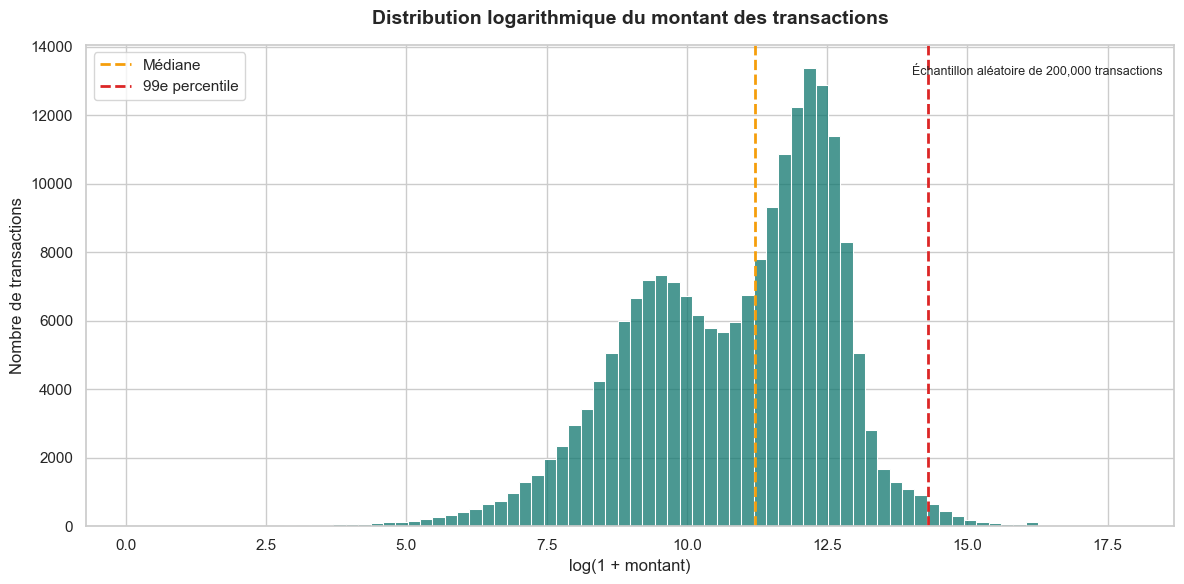

In [64]:
# Analyser les valeurs extrêmes du montant
if "amount" in df.columns:
    amount_quantiles = df["amount"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999, 1]
    ).to_frame("Montant")

    display(amount_quantiles)

    positive_amounts = df.loc[df["amount"] > 0, "amount"]
    max_plot_rows = 200_000

    if len(positive_amounts) > max_plot_rows:
        amount_sample = positive_amounts.sample(
            n=max_plot_rows,
            random_state=RANDOM_STATE,
        )
        sample_note = f"Échantillon aléatoire de {max_plot_rows:,} transactions"
    else:
        amount_sample = positive_amounts
        sample_note = "Ensemble des montants positifs"

    log_amount = np.log1p(amount_sample)
    median_log = np.log1p(df["amount"].median())
    percentile_99_log = np.log1p(df["amount"].quantile(0.99))

    fig, ax = plt.subplots(figsize=(12, 6))

    sns.histplot(
        log_amount,
        bins=80,
        color=COLORS["secondary"],
        ax=ax,
    )

    ax.axvline(
        median_log,
        color=COLORS["warning"],
        linestyle="--",
        linewidth=2,
        label="Médiane",
    )

    ax.axvline(
        percentile_99_log,
        color=COLORS["fraud"],
        linestyle="--",
        linewidth=2,
        label="99e percentile",
    )

    ax.set_title(
        "Distribution logarithmique du montant des transactions",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    ax.set_xlabel("log(1 + montant)")
    ax.set_ylabel("Nombre de transactions")
    ax.text(
        0.99,
        0.96,
        sample_note,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )
    ax.legend()

    plt.tight_layout()
    plt.show()

In [65]:
# Comparer les montants selon la cible
if {"amount", "isFraud"}.issubset(df.columns):
    amount_by_target = (
        df.groupby("isFraud", observed=True)["amount"]
        .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    )

    display(amount_by_target)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
isFraud,,,,,,,,,,,
0,"6,354,407.00","178,197.04","596,236.98",0.01,"13,368.40","74,684.72","208,364.76","364,373.44","515,610.42","1,586,064.17","92,445,516.64"
1,"8,213.00","1,467,967.30","2,404,252.95",0.00,"127,091.33","441,423.44","1,517,771.48","4,521,723.51","8,006,429.04","10,000,000.00","10,000,000.00"


### Observation

Les contrôles couvrent les valeurs négatives, les montants nuls, les transactions auto-adressées, les écarts comptables apparents et les valeurs extrêmes.

### Interprétation

Une valeur extrême peut être une erreur, une convention du simulateur, un comportement rare ou un signal de fraude.

### Impact sur le projet

Les modèles linéaires et neuronaux peuvent être sensibles à ces valeurs.

### Décision

Aucune valeur atypique n'est supprimée à ce stade.

# 15. Contraintes et limites du dataset

## Ce que PaySim permet d'étudier

- caractéristiques transactionnelles ;
- relations entre comptes ;
- évolution temporelle ;
- comparaison ML, GNN statique et GNN dynamique ;
- impact du déséquilibre de classes.

## Informations absentes ou limitées

- géolocalisation réelle ;
- opérateur Mobile Money ;
- appareil et adresse IP ;
- informations KYC ;
- historique d'enquêtes ;
- identifiant transactionnel unique ;
- labels issus d'un système réel.

## Limites méthodologiques

- données synthétiques ;
- fort déséquilibre ;
- risque de fuite temporelle ;
- règles propres au simulateur ;
- généralisation limitée vers un environnement réel.

In [66]:
# Résumer les contraintes
constraints = pd.DataFrame(
    [
        (
            "Volume",
            f"{len(df):,} transactions",
            "Vectoriser et optimiser la mémoire.",
        ),
        (
            "Déséquilibre",
            f"{fraud_rate:.6f} % de fraude",
            "Utiliser des métriques adaptées.",
        ),
        (
            "Temporalité",
            f"{n_unique_steps:,} steps",
            "Adopter un split chronologique.",
        ),
        (
            "Structure relationnelle",
            f"{len(all_accounts):,} comptes uniques",
            "Construire un graphe orienté.",
        ),
        (
            "Identifiants",
            "Forte cardinalité",
            "Éviter le One-Hot Encoding.",
        ),
        (
            "Nature",
            "Dataset synthétique",
            "Limiter les conclusions opérationnelles.",
        ),
    ],
    columns=["Contrainte", "Constat", "Conséquence méthodologique"],
)

display(constraints)

,Contrainte,Constat,Conséquence méthodologique
0,Volume,"6,362,620 transactions",Vectoriser et optimiser la mémoire.
1,Déséquilibre,0.129082 % de fraude,Utiliser des métriques adaptées.
2,Temporalité,743 steps,Adopter un split chronologique.
3,Structure relationnelle,"9,073,900 comptes uniques",Construire un graphe orienté.
4,Identifiants,Forte cardinalité,Éviter le One-Hot Encoding.
5,Nature,Dataset synthétique,Limiter les conclusions opérationnelles.


### Observation

PaySim réunit les dimensions tabulaire, relationnelle et temporelle nécessaires au projet.

### Interprétation

Il convient à une preuve de concept académique, mais ne reproduit pas toute la complexité d'un système réel.

### Impact sur le projet

Le mémoire devra distinguer performance expérimentale et validité opérationnelle.

### Décision

Le projet sera présenté comme un prototype méthodologique évalué sur données synthétiques.

## 15.7 Sauvegarde des résultats de compréhension des données

Les tableaux principaux sont enregistrés afin de pouvoir être réutilisés dans le mémoire, le README et le dashboard sans recalculer immédiatement toutes les analyses.

In [67]:
# Créer le dossier de rapports
summary_dir = project_root / "reports" / "data_understanding"
summary_dir.mkdir(parents=True, exist_ok=True)

# Enregistrer les principaux tableaux
tables_to_export = {
    "loading_summary.csv": loading_summary,
    "data_dictionary.csv": data_dictionary,
    "missing_summary.csv": missing_summary.reset_index(),
    "target_distribution.csv": target_distribution.reset_index(),
    "type_distribution.csv": type_distribution.reset_index(),
    "fraud_by_type.csv": fraud_by_type.reset_index(),
    "temporal_activity_by_day.csv": activity_by_day.reset_index(),
    "constraints.csv": constraints,
}

for filename, table in tables_to_export.items():
    table.to_csv(
        summary_dir / filename,
        index=False,
        encoding="utf-8-sig",
    )

# Enregistrer une synthèse au format JSON
summary_json = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "memory_mb": float(memory_mb),
    "fraud_count": int(n_fraud),
    "fraud_rate_percent": float(fraud_rate),
    "imbalance_ratio": float(imbalance_ratio),
    "unique_accounts": int(len(all_accounts)),
    "unique_steps": int(n_unique_steps),
    "estimated_days": int(estimated_days),
    "missing_values": int(total_missing),
    "complete_duplicate_rows": int(n_complete_duplicate_rows),
    "fraud_transaction_types": types_with_fraud,
}

with open(
    summary_dir / "data_understanding_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary_json,
        file,
        ensure_ascii=False,
        indent=4,
    )

print(f"Résultats enregistrés dans : {summary_dir}")

Résultats enregistrés dans : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\data_understanding


# 16. Executive Summary

La cellule suivante génère une synthèse à partir des résultats réellement obtenus.

In [68]:
# Préparer les informations de synthèse
top_transaction_type = type_distribution.index[0]
top_transaction_share = type_distribution.iloc[0]["Pourcentage (%)"]

fraud_types_text = ", ".join(types_with_fraud) if types_with_fraud else "aucun type"
missing_text = (
    "aucune valeur manquante explicite"
    if total_missing == 0
    else f"{total_missing:,} valeurs manquantes"
)
duplicate_text = (
    "aucun doublon complet"
    if n_complete_duplicate_rows == 0
    else f"{n_complete_duplicate_rows:,} lignes dans des doublons complets"
)

display(
    Markdown(
        f"""
## Synthèse exécutive du Notebook 01

### Structure générale

Le fichier contient **{len(df):,} transactions** et **{df.shape[1]} variables**.  
Il occupe environ **{memory_mb:,.2f} Mo en mémoire**.

### Qualité des données

- Valeurs manquantes : **{missing_text}**.
- Doublons : **{duplicate_text}**.
- Les écarts comptables sont considérés comme des anomalies apparentes à étudier.

### Variable cible

Le dataset contient **{n_fraud:,} fraudes**, soit **{fraud_rate:.6f} %** des transactions.  
Le rapport est d'environ **1 fraude pour {imbalance_ratio:,.2f} transactions légitimes**.

### Types de transactions

Le type le plus fréquent est **{top_transaction_type}**, avec **{top_transaction_share:.2f} %** des transactions.  
Les fraudes observées concernent : **{fraud_types_text}**.

### Structure relationnelle

Le dataset contient environ **{len(all_accounts):,} comptes uniques**.  
`nameOrig` et `nameDest` serviront à construire un graphe orienté.

### Dimension temporelle

La simulation contient **{n_unique_steps:,} steps**, soit environ **{estimated_days} jours** si un step équivaut à une heure.

### Décisions méthodologiques

1. Conserver toutes les transactions pour l'EDA.
2. Ne supprimer aucune valeur atypique sans justification.
3. Utiliser un découpage chronologique.
4. Ne pas sélectionner un modèle uniquement sur l'accuracy.
5. Évaluer recall, précision, F1, PR-AUC, ROC-AUC et coûts métier.
6. Représenter les comptes comme nœuds et les transactions comme arêtes.
7. Présenter les résultats comme une preuve de concept sur données synthétiques.

### Prochaine étape

Le **Notebook 02 — EDA approfondie** analysera :

- les montants et soldes ;
- les différences fraude/légitime ;
- les comportements par type ;
- les dynamiques temporelles ;
- les comptes et motifs relationnels ;
- les premières hypothèses de Feature Engineering.
"""
    )
)


## Synthèse exécutive du Notebook 01

### Structure générale

Le fichier contient **6,362,620 transactions** et **11 variables**.  
Il occupe environ **706.22 Mo en mémoire**.

### Qualité des données

- Valeurs manquantes : **aucune valeur manquante explicite**.
- Doublons : **aucun doublon complet**.
- Les écarts comptables sont considérés comme des anomalies apparentes à étudier.

### Variable cible

Le dataset contient **8,213 fraudes**, soit **0.129082 %** des transactions.  
Le rapport est d'environ **1 fraude pour 773.70 transactions légitimes**.

### Types de transactions

Le type le plus fréquent est **CASH_OUT**, avec **35.17 %** des transactions.  
Les fraudes observées concernent : **CASH_OUT, TRANSFER**.

### Structure relationnelle

Le dataset contient environ **9,073,900 comptes uniques**.  
`nameOrig` et `nameDest` serviront à construire un graphe orienté.

### Dimension temporelle

La simulation contient **743 steps**, soit environ **31 jours** si un step équivaut à une heure.

### Décisions méthodologiques

1. Conserver toutes les transactions pour l'EDA.
2. Ne supprimer aucune valeur atypique sans justification.
3. Utiliser un découpage chronologique.
4. Ne pas sélectionner un modèle uniquement sur l'accuracy.
5. Évaluer recall, précision, F1, PR-AUC, ROC-AUC et coûts métier.
6. Représenter les comptes comme nœuds et les transactions comme arêtes.
7. Présenter les résultats comme une preuve de concept sur données synthétiques.

### Prochaine étape

Le **Notebook 02 — EDA approfondie** analysera :

- les montants et soldes ;
- les différences fraude/légitime ;
- les comportements par type ;
- les dynamiques temporelles ;
- les comptes et motifs relationnels ;
- les premières hypothèses de Feature Engineering.


# Conclusion

Ce notebook établit la base méthodologique du projet sans introduire prématurément de transformations.

Les résultats alimenteront :

- le chapitre de présentation des données ;
- le protocole expérimental ;
- l'EDA ;
- la construction du graphe ;
- le dashboard analytique.